# Практическая работа №5. Библиотека Pandas. Визуальный анализ данных

## Комплексное задание №1. Применение основных методов для анализа данных

1. Скачайте этот блокнот к себе.
2. Заполните пропущенные ячейки, отвечая на заданные вопросы. Там должен быть код! (если не сказано обратное)
3. Сохраните результат в своём гитхаб репозитории.

#### Полезная литература
- [**Блокнот с теорией**](https://colab.research.google.com/drive/1SLqmaYz4xEsxVV-LGwb3ityheBTzHJQu?usp=sharing)
- http://pandas.pydata.org/pandas-docs/stable/10min.html
- https://pandas.pydata.org/pandas-docs/stable/indexing.html
- https://pandas.pydata.org/pandas-docs/stable/missing_data.html

В этом задании мы с Вами рассмотрим датасет [Adult Data Set](https://archive.ics.uci.edu/ml/datasets/Adult).
Основывается он на данных переписи населения 1994 года в США.

Расшифровка содержимого колонок:

- age: continuous.
- workclass: Private, Self-emp-not-inc, Self-emp-inc, Federal-gov, Local-gov, State-gov, Without-pay, Never-worked.
- fnlwgt: continuous. sampling weight, more here: SIPP Weighting.
- education: Bachelors, Some-college, 11th, HS-grad, Prof-school, Assoc-acdm, Assoc-voc, 9th, 7th-8th, 12th, Masters, 1st-4th, 10th, Doctorate, 5th-6th, Preschool.
- education-num: continuous.
- marital-status: Married-civ-spouse, Divorced, Never-married, Separated, Widowed, Married-spouse-absent, Married-AF-spouse.
- occupation: Tech-support, Craft-repair, Other-service, Sales, Exec-managerial, Prof-specialty, Handlers-cleaners, Machine-op-inspct, Adm-clerical, Farming-fishing, Transport-moving, Priv-house-serv, Protective-serv, Armed-Forces.
- relationship: Wife, Own-child, Husband, Not-in-family, Other-relative, Unmarried.
- race: White, Asian-Pac-Islander, Amer-Indian-Eskimo, Other, Black.
- sex: Female, Male.
- capital-gain: continuous. Income from investment sources, apart from wages/salary.
- capital-loss: continuous. Losses from investment sources, apart from wages/salary.
- hours-per-week: continuous.
- native-country: United-States, Cambodia, England, Puerto-Rico, Canada, Germany, Outlying-US(Guam-USVI-etc), India, Japan, Greece, South, China, Cuba, Iran, Honduras, Philippines, Italy, Poland, Jamaica, Vietnam, Mexico, Portugal, Ireland, France, Dominican-Republic, Laos, Ecuador, Taiwan, Haiti, Columbia, Hungary, Guatemala, Nicaragua, Scotland, Thailand, Yugoslavia, El-Salvador, Trinadad&Tobago, Peru, Hong, Holand-Netherlands.

In [6]:
%matplotlib inline
import pandas as pd
pd.__version__

'3.0.3'

Если вы увидели warning, не переживайте, всё хорошо.
- https://stackoverflow.com/questions/40845304/runtimewarning-numpy-dtype-size-changed-may-indicate-binary-incompatibility
- https://github.com/numpy/numpy/pull/432

In [7]:
columns='age,workclass,fnlwgt,education,education.num,marital.status,occupation,relationship,race,sex,capital.gain,capital.loss,hours.per.week,native.country,income'.split(',')
# df = pd.read_csv('../../data/adult.csv.gz', na_values='?') # можно загрузить из файла или URL
df = pd.read_csv('https://archive.ics.uci.edu/ml/machine-learning-databases/adult/adult.data', na_values=' ?', names=columns)
df.head()

,age,workclass,fnlwgt,education,education.num,marital.status,occupation,relationship,race,sex,capital.gain,capital.loss,hours.per.week,native.country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


In [8]:
# Датасет уже загружен в df выше
df

,age,workclass,fnlwgt,education,education.num,marital.status,occupation,relationship,race,sex,capital.gain,capital.loss,hours.per.week,native.country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
32556,27,Private,257302,Assoc-acdm,12,Married-civ-spouse,Tech-support,Wife,White,Female,0,0,38,United-States,<=50K
32557,40,Private,154374,HS-grad,9,Married-civ-spouse,Machine-op-inspct,Husband,White,Male,0,0,40,United-States,>50K
32558,58,Private,151910,HS-grad,9,Widowed,Adm-clerical,Unmarried,White,Female,0,0,40,United-States,<=50K
32559,22,Private,201490,HS-grad,9,Never-married,Adm-clerical,Own-child,White,Male,0,0,20,United-States,<=50K


1) Выведите последние 10 элеметнов датасета

In [9]:
a = df.tail(10)
a

,age,workclass,fnlwgt,education,education.num,marital.status,occupation,relationship,race,sex,capital.gain,capital.loss,hours.per.week,native.country,income
32551,32,Private,34066,10th,6,Married-civ-spouse,Handlers-cleaners,Husband,Amer-Indian-Eskimo,Male,0,0,40,United-States,<=50K
32552,43,Private,84661,Assoc-voc,11,Married-civ-spouse,Sales,Husband,White,Male,0,0,45,United-States,<=50K
32553,32,Private,116138,Masters,14,Never-married,Tech-support,Not-in-family,Asian-Pac-Islander,Male,0,0,11,Taiwan,<=50K
32554,53,Private,321865,Masters,14,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,40,United-States,>50K
32555,22,Private,310152,Some-college,10,Never-married,Protective-serv,Not-in-family,White,Male,0,0,40,United-States,<=50K
32556,27,Private,257302,Assoc-acdm,12,Married-civ-spouse,Tech-support,Wife,White,Female,0,0,38,United-States,<=50K
32557,40,Private,154374,HS-grad,9,Married-civ-spouse,Machine-op-inspct,Husband,White,Male,0,0,40,United-States,>50K
32558,58,Private,151910,HS-grad,9,Widowed,Adm-clerical,Unmarried,White,Female,0,0,40,United-States,<=50K
32559,22,Private,201490,HS-grad,9,Never-married,Adm-clerical,Own-child,White,Male,0,0,20,United-States,<=50K
32560,52,Self-emp-inc,287927,HS-grad,9,Married-civ-spouse,Exec-managerial,Wife,White,Female,15024,0,40,United-States,>50K


2) Сколько колонок и сколько строк в этом датасете?

In [10]:
a = df.shape
print("Строк:", a[0])
print("Колонок:", a[1])

Строк: 32561
Колонок: 15


3) Какие типы данных у элементов этого датасета?

In [31]:
print(df.dtypes)

age               int64
workclass           str
fnlwgt            int64
education           str
education.num     int64
marital.status      str
occupation          str
relationship        str
race                str
sex                 str
capital.gain      int64
capital.loss      int64
hours.per.week    int64
native.country      str
income              str
dtype: object


4) Какие признаки имеют пропуски?

In [12]:
a = df.isna().sum()
a[a > 0]

workclass         1836
occupation        1843
native.country     583
dtype: int64

5) Как вы думаете, с чем связаны пропуски этих значение. Напишите развернутый ответ в ячейке ниже.

Ваш ответ:

во время сбора данных люди просто не указывали остальные данные о себе

6) Какие и сколько различных рабочих классов workclass представлено в выборке?

In [35]:
df["workclass"].value_counts(dropna=False)

workclass
 Private             22696
 Self-emp-not-inc     2541
 Local-gov            2093
NaN                   1836
 State-gov            1298
 Self-emp-inc         1116
 Federal-gov           960
 Without-pay            14
 Never-worked            7
Name: count, dtype: int64

7) Какой средний возраст женщин и мужчин?

In [86]:
df.groupby("sex")["age"].mean()

sex
Female    36.858230
Male      39.433547
Name: age, dtype: float64

8) Постройте гистограмму(bar) распределения образования людей (education)

<Axes: xlabel='education'>

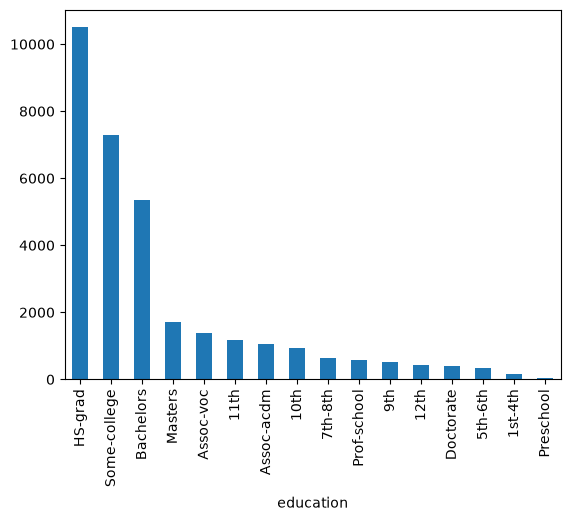

In [85]:
df["education"].value_counts().plot(kind="bar")

9) Каковы средние значения и среднеквадратичные отклонения возраста тех, кто получает более 50K в год (признак income) и тех, кто получает менее 50K в год?

In [80]:
stats = df.groupby('income')['age'].describe()
print(f"Среднее значение возраста тех, кто получает <=50K в год: {stats['mean'].iloc[0]}")
print(f"Среднее значение возраста тех, кто получает >50K в год: {stats['mean'].iloc[1]}")
print(f"Среднеквадратичное отклонение возраста тех, кто получает <=50K в год: {stats['std'].iloc[0]}")
print(f"Среднеквадратичное отклонение возраста тех, кто получает >50K в год: {stats['std'].iloc[1]}")
print(stats['mean'], stats['std'])

Среднее значение возраста тех, кто получает <=50K в год: 36.78373786407767
Среднее значение возраста тех, кто получает >50K в год: 44.24984058155847
Среднеквадратичное отклонение возраста тех, кто получает <=50K в год: 14.02008849082488
Среднеквадратичное отклонение возраста тех, кто получает >50K в год: 10.519027719851826
income
<=50K    36.783738
>50K     44.249841
Name: mean, dtype: float64 income
<=50K    14.020088
>50K     10.519028
Name: std, dtype: float64


10) Правда ли, что люди, которые получают больше 50k, имеют как минимум высшее образование? (признак education - Bachelors, Prof-school, Assoc-acdm, Assoc-voc, Masters или Doctorate)

In [81]:
a = ["Bachelors", "Prof-school", "Assoc-acdm", "Assoc-voc", "Masters", "Doctorate"]
b = df[df["income"] == " >50K"]
c = (~b["education"].isin(a)).sum()

print("Людей с доходом >50K без указанного высшего образования:", c)
print("Утверждение верно:", c == 0)

Людей с доходом >50K без указанного высшего образования: 7841
Утверждение верно: False


11) Среди кого больше доля зарабатывающих много (>50K): среди женатых или холостых мужчин (признак marital-status)? Женатыми считаем тех, у кого marital-status начинается с Married (Married-civ-spouse, Married-spouse-absent или Married-AF-spouse), остальных считаем холостыми.

In [82]:
a = df[df["sex"] == " Male"]

b = a[a["marital.status"].str.startswith(" Married")]
c = a[~a["marital.status"].str.startswith(" Married")]

print("Женатые:", (b["income"] == " >50K").sum())
print("Холостые:", (c["income"] == " >50K").sum())

Женатые: 5965
Холостые: 697


12) Постройте [сводную таблицу](https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.pivot_table.html) для отображения зависимостей среднего времени работы (hours.per.week) с доходом (income) для каждой страны (native.country).  


> Пример фрагмента таблицы:



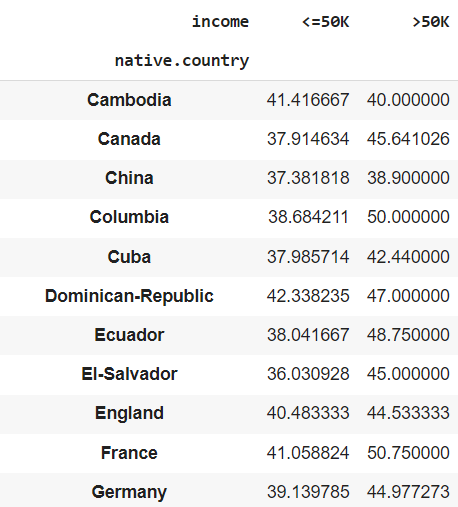

In [78]:
pd.pivot_table(df, values="hours.per.week", index=["native.country"], columns=["income"], aggfunc="mean")


income,<=50K,>50K
native.country,,
Cambodia,41.416667,40.000000
Canada,37.914634,45.641026
China,37.381818,38.900000
Columbia,38.684211,50.000000
Cuba,37.985714,42.440000
Dominican-Republic,42.338235,47.000000
Ecuador,38.041667,48.750000
El-Salvador,36.030928,45.000000
England,40.483333,44.533333


13) Постройте сводную таблицу для сравнения уровня образования и разности между capital.gain и capital.loss по следующему алгоритму:&nbsp;  
1. Создайте вспомогательную таблицу (датафрейм) и добавьте в неё столбец "education" из целевой таблицы
2. Добавьте во вспомогательную таблицу ещё один столбец "capital.diff", значиниями которого будут являться разности столбцов capital.gain и capital.loss целевой таблицы
3. Удалите во вспомогательной таблице все строки, в которых значение столбца "capital.diff" равно нулю  
&nbsp; Подсказка:
```
summary_table = summary_table[summary_table['capital.diff'] != 0 ]
```
4. Для набора значений из столбца "capital.diff", необходимо сформировать 10 категорий (кластеров), это можно сделать с помощью математических функций, типа log, извлечение корня N-ой степени и округления, для последующего перехода к категориальным признакам.  
  * В нашем случае, можно воспользоваться методом [pd.qcut()](https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.qcut.html) и равномерно разделить наш набор данных на целевое количество категорий
5. Добавьте во вспомогательную таблицу столбец "categories", и проинициализируйте его значениями категорий, которые возвращает метод pd.qcut()  
&nbsp; Пример:
```
summary_table['categories'] = pd.qcut(summary_table["capital.diff"], q = 10)

6. Постройте сводную таблицу с помощью метода pivot_table(),

Примерная структура таблицы (в качестве значений выводится количество людей, относящихся к той или иной группе):

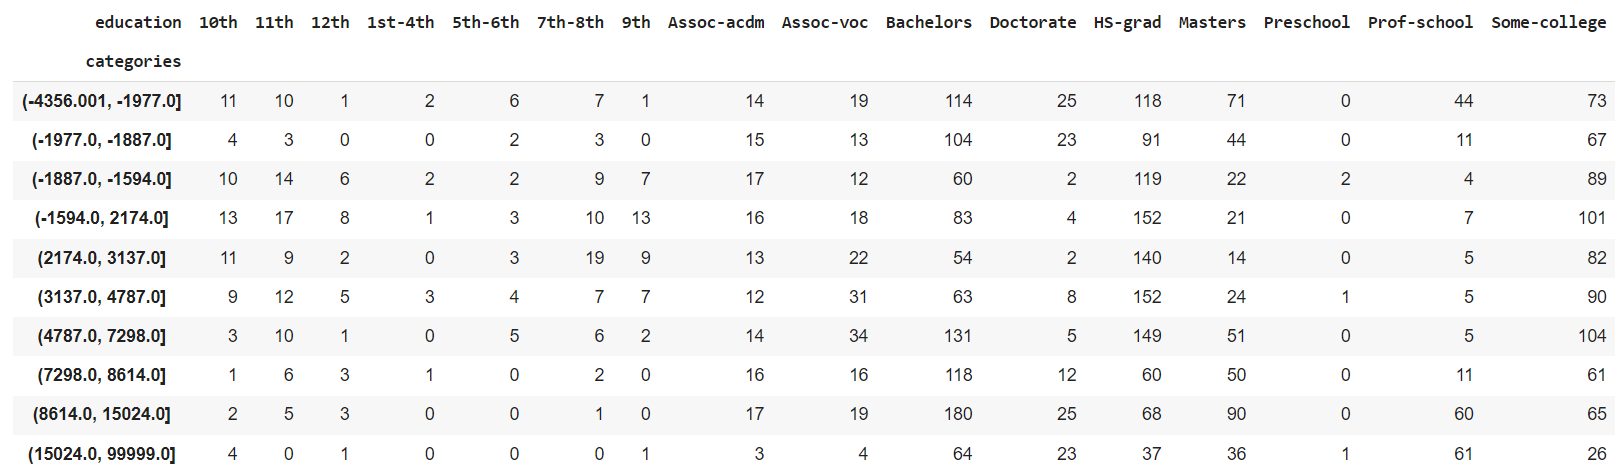

In [84]:
a = pd.DataFrame()
a["education"] = df["education"]
a["capital.diff"] = df["capital.gain"] - df["capital.loss"]
a = a[a["capital.diff"] != 0].copy()

b = min(10, a["capital.diff"].nunique())
a["categories"] = pd.qcut(a["capital.diff"], q=b, duplicates="drop")

pd.pivot_table(a, values="capital.diff", index="education", columns="categories", aggfunc="count", fill_value=0)


categories,"(-4356.001, -1977.0]","(-1977.0, -1887.0]","(-1887.0, -1594.0]","(-1594.0, 2174.0]","(2174.0, 3137.0]","(3137.0, 4787.0]","(4787.0, 7298.0]","(7298.0, 8614.0]","(8614.0, 15024.0]","(15024.0, 99999.0]"
education,,,,,,,,,,
10th,11,4,10,13,11,9,3,1,2,4
11th,10,3,14,17,9,12,10,6,5,0
12th,1,0,6,8,2,5,1,3,3,1
1st-4th,2,0,2,1,0,3,0,1,0,0
5th-6th,6,2,2,3,3,4,5,0,0,0
7th-8th,7,3,9,10,19,7,6,2,1,0
9th,1,0,7,13,9,7,2,0,0,1
Assoc-acdm,14,15,17,16,13,12,14,16,17,3
Assoc-voc,19,13,12,18,22,31,34,16,19,4


14) Женщины из каких стран получают в среднем большую зарплату (>50K) чаще.

In [83]:
df_f = df[df['sex'] == ' Female']
df_f['high_income'] = df_f['income'] == ' >50K'
df_f.groupby('native.country')['high_income'].mean().sort_values(ascending=False)

native.country
Yugoslavia                    0.333333
Taiwan                        0.266667
France                        0.250000
Iran                          0.250000
Japan                         0.250000
Italy                         0.238095
China                         0.238095
Canada                        0.230769
Greece                        0.200000
Scotland                      0.200000
England                       0.187500
India                         0.181818
Portugal                      0.166667
Hong                          0.166667
Hungary                       0.166667
Philippines                   0.164384
Honduras                      0.142857
Ireland                       0.142857
Laos                          0.125000
Germany                       0.116667
United-States                 0.110721
Poland                        0.105263
South                         0.100000
Thailand                      0.090909
Nicaragua                     0.083333
Cuba      

15) Создайте случайную колонку - magic_salary, которую нужно будет вычислить следующим образом: если зарплата небольшая (<50K), тогда случайно выберите число из диапазона [0,50]. Если зарплата выше 50K тогда из диапазона [51, 200]. Посчитайте среднюю зарплату в час для групп людей с одни уровнем образования на основе нашей случайной колонки magic_salary

In [22]:
import numpy as np

a = df.copy()
b = a["income"] == " >50K"

a["magic_salary"] = np.where(
    b,
    np.random.randint(51, 201, len(a)),
    np.random.randint(0, 51, len(a))
)

a["salary_per_hour"] = a["magic_salary"] / a["hours.per.week"]
a.groupby("education")["salary_per_hour"].mean().sort_values(ascending=False)

education
Doctorate       2.615310
Prof-school     2.333466
Masters         2.203095
Bachelors       1.679974
Assoc-acdm      1.503133
Assoc-voc       1.347375
Some-college    1.267079
HS-grad         1.132668
11th            1.096383
10th            1.073157
7th-8th         1.039539
12th            1.034604
9th             0.942222
1st-4th         0.906419
5th-6th         0.889663
Preschool       0.866397
Name: salary_per_hour, dtype: float64

## Комплексное задание №2. Визуальный анализ данных. Часть 1

In [95]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
import seaborn as sns
%matplotlib inline

В этом задании Вам предлагается провести визуальный анализ датасета о прокатах велосипедов https://www.kaggle.com/c/bike-sharing-demand/data. Оригинальная задача предполагает построение модели предсказания количества прокатов в городе в зависимости от погоды.

Для каждого дня проката известны следующие признаки (как они были указаны в источнике данных):
- season: 1 - весна, 2 - лето, 3 - осень, 4 - зима
- yr: 0 - 2011, 1 - 2012
- mnth: от 1 до 12
- holiday: 0 - нет праздника, 1 - есть праздник
- weekday: от 0 до 6
- workingday: 0 - нерабочий день, 1 - рабочий день
- weathersit: оценка благоприятности погоды от 1 (чистый, ясный день) до 4 (ливень, туман)
- temp: температура в Цельсиях
- atemp: температура по ощущениям в Цельсиях
- hum: влажность
- windspeed(mph): скорость ветра в милях в час
- windspeed(ms): скорость ветра в метрах в секунду
- cnt: количество арендованных велосипедов (это целевой признак, его мы будем предсказывать)

Загрузите самостоятельно(!), с помощью pandas файл `bikes_rent.csv.gz` и выведите первые 5 строк. Ознакомьтесь с данными с помощью функций describe и info.

In [98]:
df = pd.read_csv('https://raw.githubusercontent.com/Yorko/mlcourse.ai/main/data/bikes_rent.csv',)
df.head()
df.info()
df.describe()

<class 'pandas.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   season          731 non-null    int64  
 1   yr              731 non-null    int64  
 2   mnth            731 non-null    int64  
 3   holiday         731 non-null    int64  
 4   weekday         731 non-null    int64  
 5   workingday      731 non-null    int64  
 6   weathersit      731 non-null    int64  
 7   temp            731 non-null    float64
 8   atemp           731 non-null    float64
 9   hum             731 non-null    float64
 10  windspeed(mph)  731 non-null    float64
 11  windspeed(ms)   731 non-null    float64
 12  cnt             731 non-null    int64  
dtypes: float64(5), int64(8)
memory usage: 74.4 KB


,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed(mph),windspeed(ms),cnt
count,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000
mean,2.496580,0.500684,6.519836,0.028728,2.997264,0.683995,1.395349,20.310776,23.717699,62.789406,12.762576,5.705220,4504.348837
std,1.110807,0.500342,3.451913,0.167155,2.004787,0.465233,0.544894,7.505091,8.148059,14.242910,5.192357,2.321125,1937.211452
min,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000,2.424346,3.953480,0.000000,1.500244,0.670650,22.000000
25%,2.000000,0.000000,4.000000,0.000000,1.000000,0.000000,1.000000,13.820424,16.892125,52.000000,9.041650,4.041864,3152.000000
50%,3.000000,1.000000,7.000000,0.000000,3.000000,1.000000,1.000000,20.431653,24.336650,62.666700,12.125325,5.420351,4548.000000
75%,3.000000,1.000000,10.000000,0.000000,5.000000,1.000000,2.000000,26.872076,30.430100,73.020850,15.625371,6.984967,5956.000000
max,4.000000,1.000000,12.000000,1.000000,6.000000,1.000000,3.000000,35.328347,42.044800,97.250000,34.000021,15.198937,8714.000000


In [99]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   season          731 non-null    int64  
 1   yr              731 non-null    int64  
 2   mnth            731 non-null    int64  
 3   holiday         731 non-null    int64  
 4   weekday         731 non-null    int64  
 5   workingday      731 non-null    int64  
 6   weathersit      731 non-null    int64  
 7   temp            731 non-null    float64
 8   atemp           731 non-null    float64
 9   hum             731 non-null    float64
 10  windspeed(mph)  731 non-null    float64
 11  windspeed(ms)   731 non-null    float64
 12  cnt             731 non-null    int64  
dtypes: float64(5), int64(8)
memory usage: 74.4 KB


Давайте посмотрим на графиках, как целевой признак зависит количество прокатов (cnt) зависит от остальных признаков `df.columns[:-1]`.

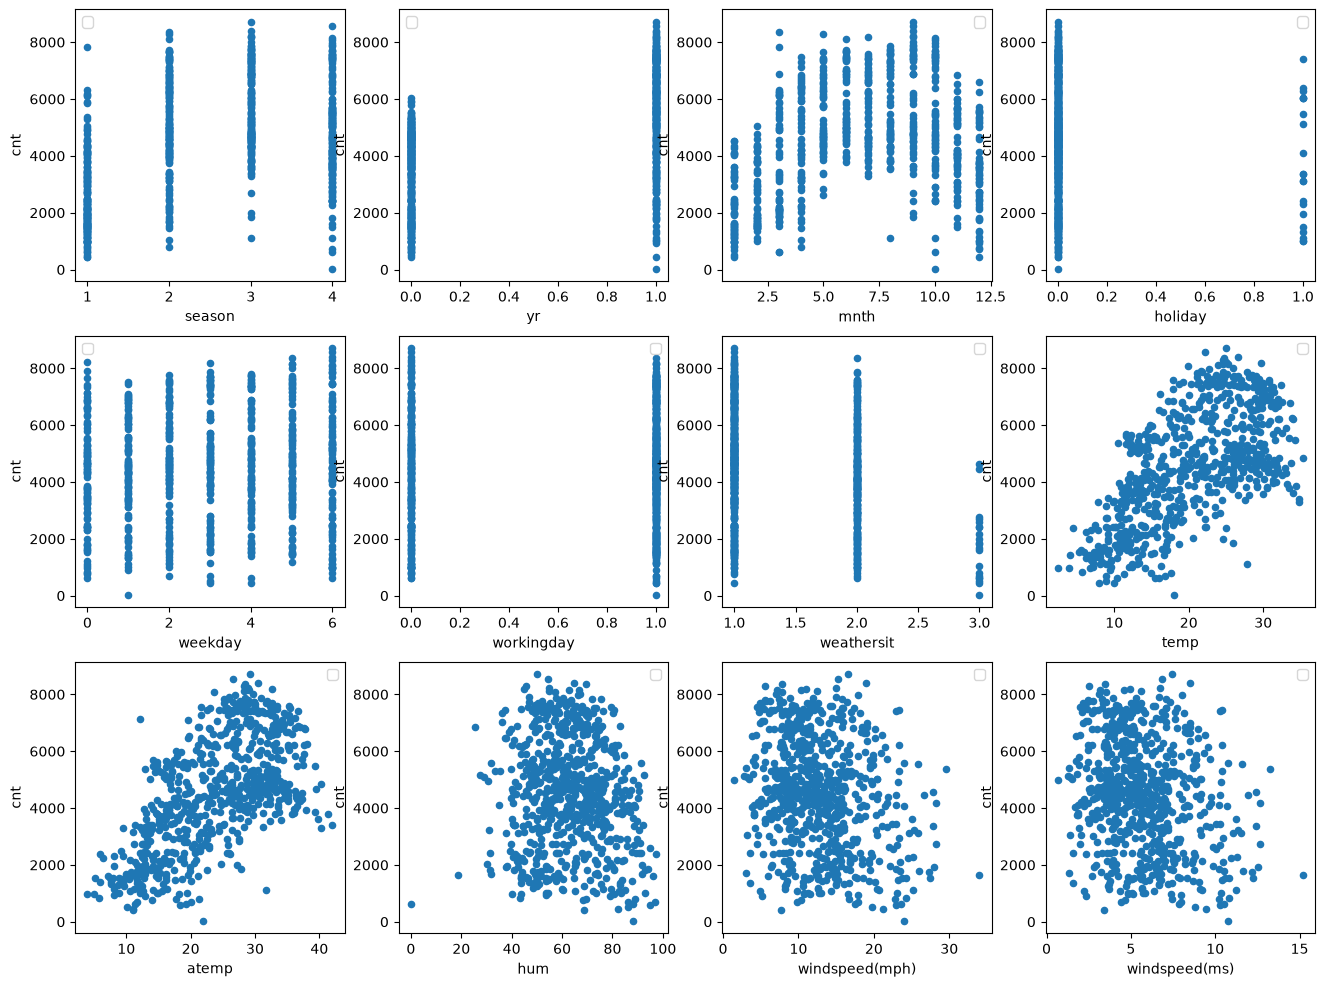

In [100]:
fig, axes = plt.subplots(nrows=3, ncols=4, figsize=(16, 12))
for idx, feature in enumerate(df.columns[:-1]):
     df.plot(feature, "cnt", subplots=True, kind="scatter", ax=axes[idx // 4, idx % 4])

### 1. Ответьте на вопросы:

#### Каков характер зависимости числа прокатов от месяца?





ответ:

сезооная зависимость: зимой прокатов меньше, затем их число растёт к тёплым месяцам и снова снижается ближе к зиме.

#### Укажите один или два признака, от которых число прокатов скорее всего зависит линейно
_(чем больше значение, тем больше прокатов или наоборот, например)_

Можете проверить результат с помощью lnplot.



Ответ:
temp & atemp

### 2. Корреляционная матрица

Напомним, что корреляция отражает взаимосвязь двух случайных величин. Она бывает положительная и отрицательная. Чем ближе коэффициент корреляции к нулю, тем меньше взаимосвязь. Чем больше абсолютная корреляци, тем взаимосвязь больше.

Постройте heatmap корреляционной матрицы. Матрица формируется средствами pandas, со стандартным значением параметров.



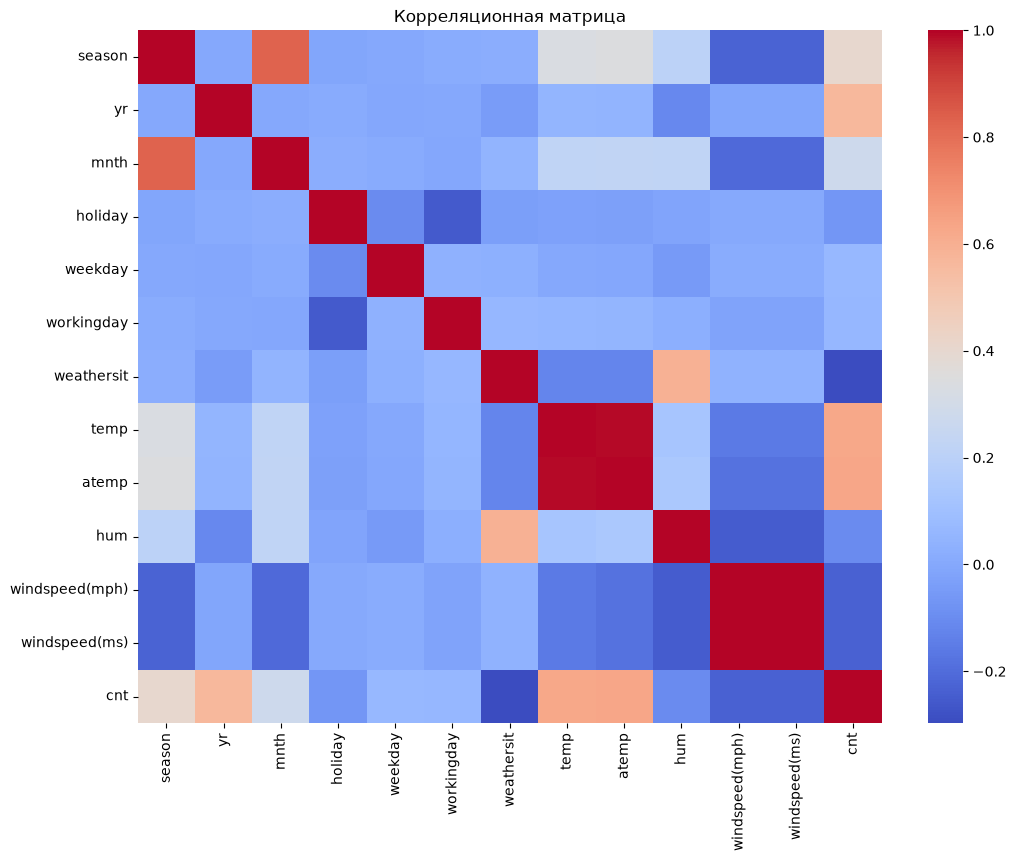

In [110]:
a = df.corr(numeric_only=True)

plt.figure(figsize=(12, 9))
sns.heatmap(a, fmt=".2f", cmap="coolwarm")
plt.title("Корреляционная матрица")
plt.show()

**Ответьте на вопрос**: с какими признаками количество прокатов коррелирует меньше всего (около 4 штуки). А с какими больше всего?

Ответ:

меньше всего с holiday, hum, weathersit, больше всего связь заметна с temp, atemp, season, yr

### 3. Barpot

Постройте Bar-график суммарного количества прокатов велосипедов по месяцам за каждый год одновременно. (будет 24 столбика)



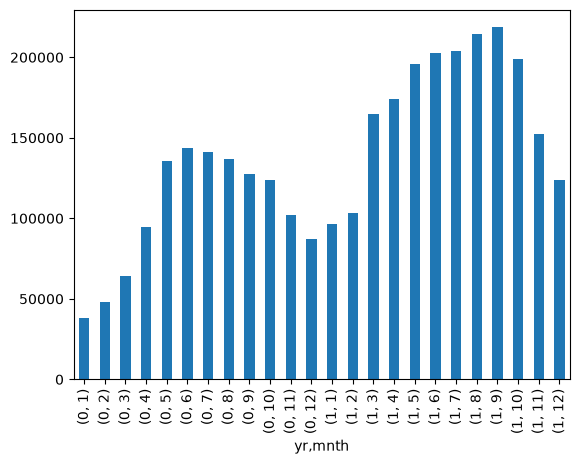

In [114]:
df.groupby(['yr', 'mnth'])['cnt'].sum().plot(kind='bar')
plt.show()

**Ответьте на вопрос:** почему в предыдущем графике была такая большая корреляция между количеством прокатов и годом?

Ответ:

в 2011 году суммарное число прокатов стало выше

### 4. Countplot

Постройте countplot диаграммы для признаков `weekday`, `weathersit`,



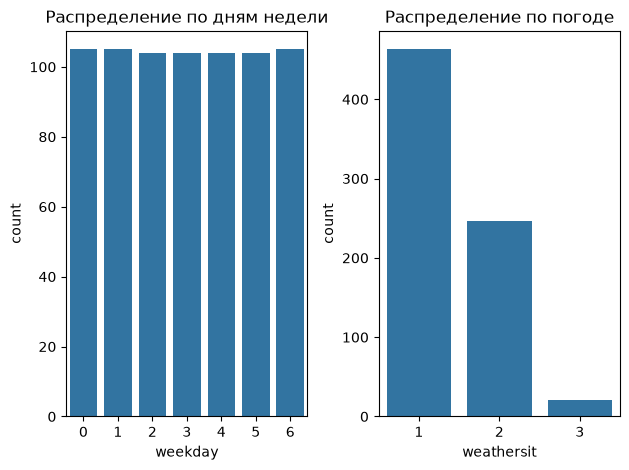

In [131]:
a, b = plt.subplots(1, 2)

sns.countplot(data=df, x="weekday", ax=b[0])
b[0].set_title("Распределение по дням недели")

sns.countplot(data=df, x="weathersit", ax=b[1])
b[1].set_title("Распределение по погоде")

plt.tight_layout()
plt.show()

**Ответьте на вопрос:** что вы можете сказать о том, как формировался этот датасет.



Ответ:



**Ответьте на вопрос:** как называется распределение значений признака `weekday`?

Ответ:




### 5. Распределение

Постройте распределение целевого признака.


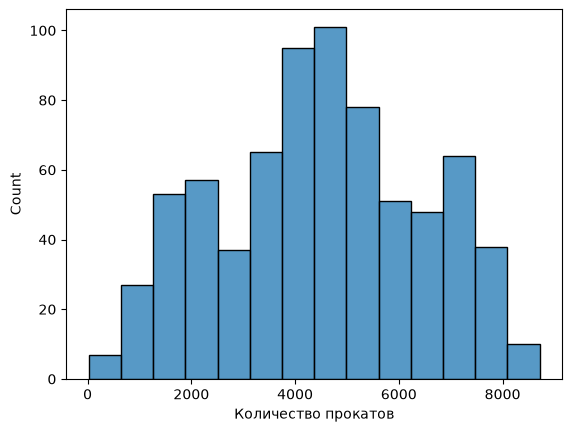

In [120]:
a = df["cnt"]
sns.histplot(a)
plt.xlabel("Количество прокатов")
plt.show()



**Ответьте на вопрос:** основываясь на графике, сколько приблизительно в среднем прокатов бывает в день?

Ответ:

около 4-5 тысяч в день

### 6. Совместное распределение признаков

Постройте график совместного распределения признаков температура и ощущение температуры.



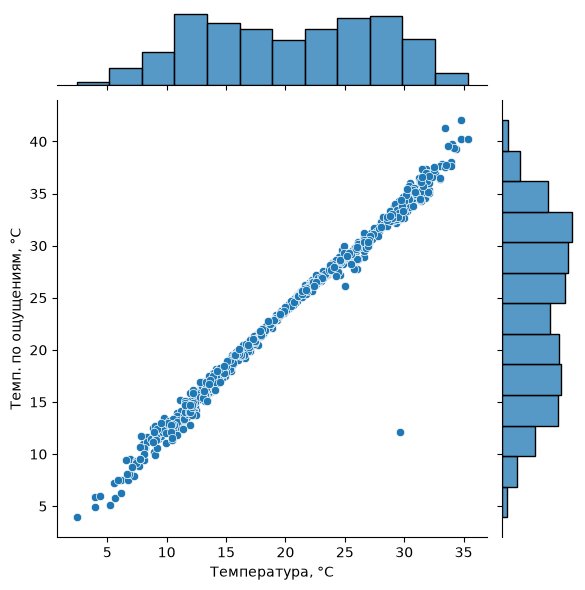

In [127]:
a = sns.jointplot(data=df, x="temp", y="atemp")
plt.xlabel('Температура, °C')
plt.ylabel('Темп. по ощущениям, °C')
plt.show()

**Ответьте на вопрос:** вас в этом графике ничего не настораживает? Почему?

Ответ:

температуры содержат очень похожу информацию, но в глаза бросается точка с температурой - 30, а по ощущениям ~13 градусов

### 7. Боксплот (ящик с усами)

Постройте график распределения (боксплот) количества прокатов велосипедов по месяцам в зависимости от того рабочий это день или нет.




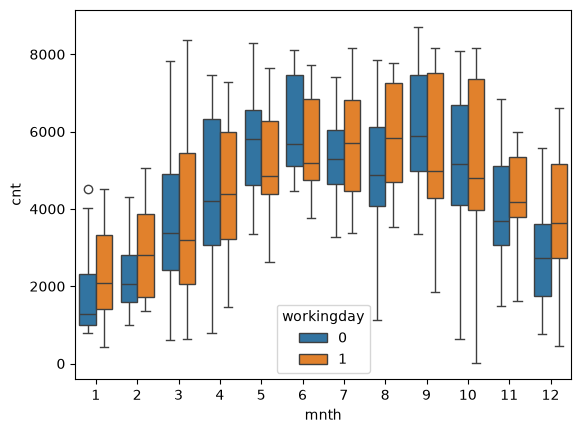

In [129]:

sns.boxplot(data=df, x="mnth", y="cnt", hue="workingday")
plt.show()

**Ответьте на вопрос:** почему в некоторых месяцах чаще берут велосипеды в будний день, а в некоторые - в выходной.

Ответ:

в теплые месяцы велосипеды чаще используют для отдыха и поездок, поэтому выходные могут давать больше прокатов, а в другие периоды заметнее регулярные поездки на работу и учебу, из-за чего выше значения в рабочие дни.

## Комплексное задание №3. Визуальный анализ данных. Часть 2

In [139]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

В этом задании Вам предлагается провести визуальный анализ датасета результатов экзаменов студентов  https://www.kaggle.com/spscientist/students-performance-in-exams.

Исходные данные загрузите самостоятельно!

In [140]:
df = pd.read_csv("StudentsPerformance.csv")
df.head()

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


### Ход задания:

#### 1. Постройте 3 графика, показывающих распределение результатов экзаменов (каждый график на предмет).


Графики должны быть в одном ряду и у них должен быть общий заголовок "Результаты экзаменов".

Для результатов каждого экзамена посчитайте медианные значения.


math score медиана: 66.0
reading score медиана: 70.0
writing score медиана: 69.0


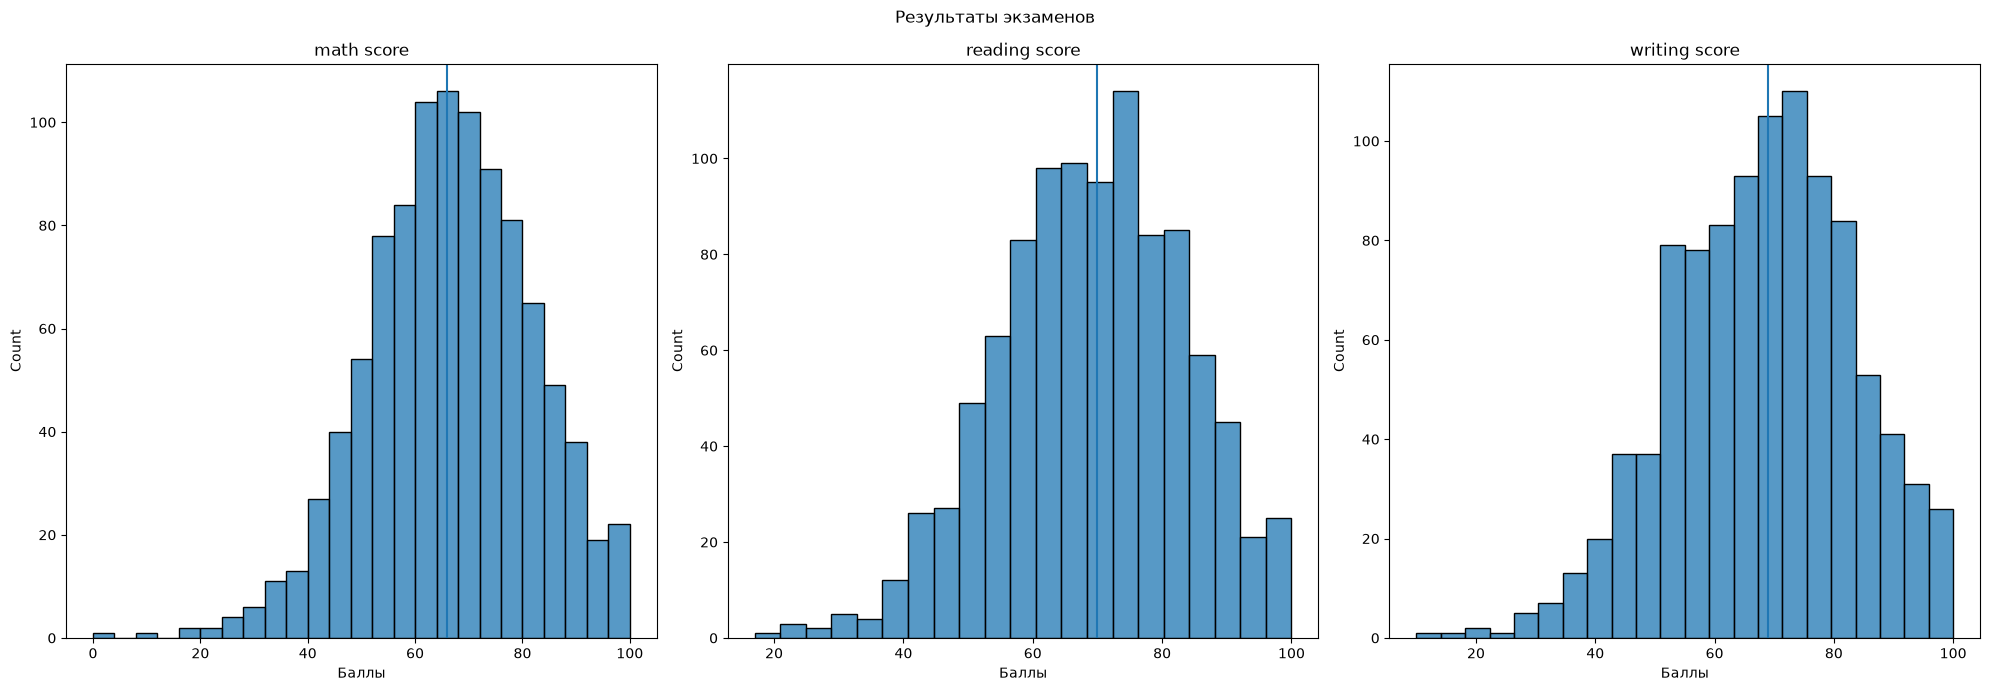

In [152]:
a = ["math score", "reading score", "writing score"]
b, c = plt.subplots(1, 3, figsize=(20,7))

for d, e in enumerate(a):
    sns.histplot(df[e], ax=c[d])
    c[d].axvline(df[e].median())
    c[d].set_title(e)
    c[d].set_xlabel("Баллы")
    print(e, "медиана:", df[e].median())

b.suptitle("Результаты экзаменов")
plt.tight_layout()
plt.show()

#### 2. Образование родителей
Какие уровни образование есть в столбце *'parental level of education'* и сколько строк в датафрейме соответствует каждому уровню?

Постройте график и ответьте на вопрос ниже

Отличаются ли баллы по математике у детей с разным образованием родителей?
Постройте график, где по оси Х находятся уровни образования родителей, а по У - баллы по математике.


parental level of education
some college          226
associate's degree    222
high school           196
some high school      179
bachelor's degree     118
master's degree        59
Name: count, dtype: int64


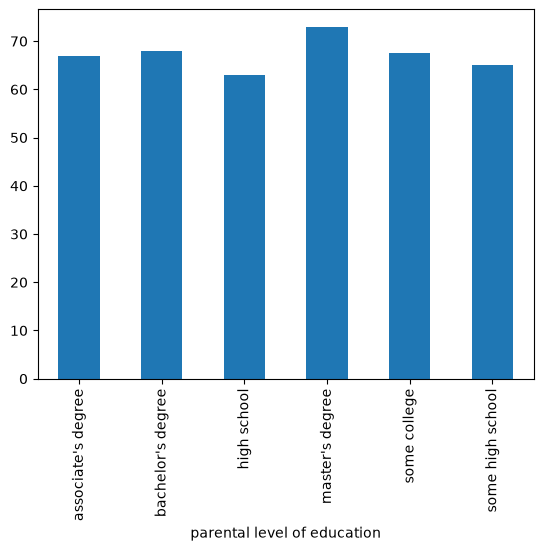

In [153]:
print(df['parental level of education'].value_counts())
df.groupby('parental level of education')['math score'].median().plot(kind='bar')
plt.show()

#### 3. Выведите число студенток, набравших больше 90 баллов по всем предметам.


In [155]:
df_f = df[df['gender'] == 'female']
df_f[(df_f['math score'] > 90 ) & (df_f['reading score'] > 90) & (df_f['writing score'] > 90)].size

136

#### 4. Сравните баллы у студентов разных полов. Используя agg() выведите минимальное, максимальное и медианное значение


In [158]:
df.groupby("gender")[["math score", "reading score", "writing score"]].agg(["min", "max", "median"])


math score             reading score             writing score       \
              min  max median           min  max median           min  max   
gender                                                                       
female          0  100   65.0            17  100   73.0            10  100   
male           27  100   69.0            23  100   66.0            15  100   

               
       median  
gender         
female   74.0  
male     64.0

#### 5. Выясните, влияет ли обед и подготовка к тесту на средний балл студентов разного пола
###### (подсказка: используете  [pd.agg()](https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.DataFrame.agg.html))

In [161]:
a = df.copy()
a["mean score"] = a[["math score", "reading score", "writing score"]].mean(axis=1)

b = a.groupby(
    ["gender", "lunch", "test preparation course"]
)["mean score"].agg(["mean", "median", "count"])

b

mean     median  count
gender lunch        test preparation course                             
female free/reduced completed                69.528571  70.333333     70
                    none                     59.501401  60.000000    119
       standard     completed                77.479532  76.000000    114
                    none                     70.961240  71.000000    215
male   free/reduced completed                65.721311  68.000000     61
                    none                     58.323810  58.333333    105
       standard     completed                73.513274  73.333333    113
                    none                     65.486043  66.666667    203

#### 6. Постройте график, показывающий зависимость уровня образования родителей от их расы

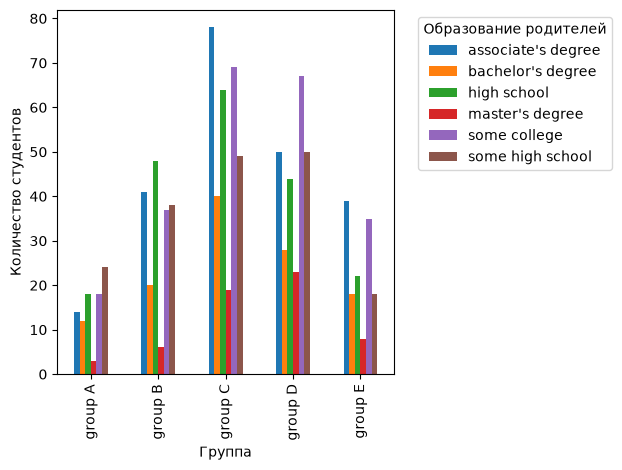

In [169]:
a = pd.crosstab(df["race/ethnicity"], df["parental level of education"]).plot(kind="bar")
plt.xlabel("Группа")
plt.ylabel("Количество студентов")
plt.legend(title="Образование родителей", bbox_to_anchor=(1.05, 1))
plt.tight_layout()
plt.show()

#### 7. Постройте график, показывающий зависимость прохождения подготовительного теста от уровня образования родителей.


Кто чаще ходит на курсы: дети, родители которых закончили только старшую школу, или дети, чьи родители получили степень бакалавра\магистра?

<Axes: xlabel='parental level of education'>

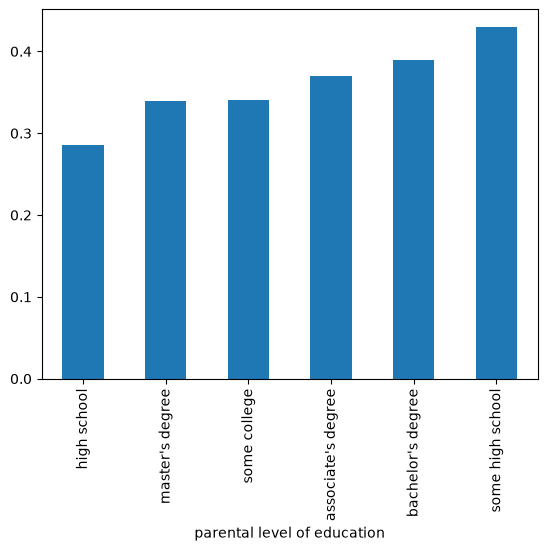

In [170]:
df['test completion'] = df['test preparation course'] == 'completed'
result = df.groupby('parental level of education')['test completion'].mean().sort_values()

result.plot(kind='bar')

# чаще ходят те, чьи родители закончили старшую школу

#### 8. Постройте plot.pie, показывающий, сколько людей сдали\не сдали экзамен по математике.

Сдавшим считается человек, набравший 40 баллов.

###### Подсказка: создайте столбец в датафрейме, который содержит результат сдачи (сдал или не сдал)

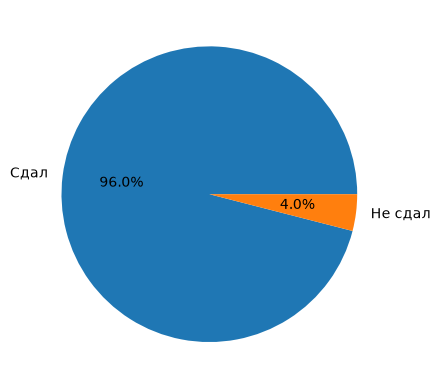

In [174]:
a = df.copy()
a["math result"] = np.where(a["math score"] >= 40, "Сдал", "Не сдал")
b = a["math result"].value_counts()

b.plot.pie(autopct="%1.1f%%")
plt.show()

#### 9. Постройте plot.pie, показывающий распределение студентов по оценкам

Оценки студентов выставляются по шкале:<br>
0  - 40 marks : grade E<br>
41 - 60 marks : grade D<br>
60 - 70 marks : grade C<br>
70 - 80 marks : grade B<br>
80 - 90 marks : grade A<br>
90 - 100 marks : grade O<br>

Для этого посчитайте сумму результатов за 3 экзамена и найдите среднее. Оценка выставляется по среднему значению. Если студент не сдал математику(даже если средний балл выше 40), он получает Е

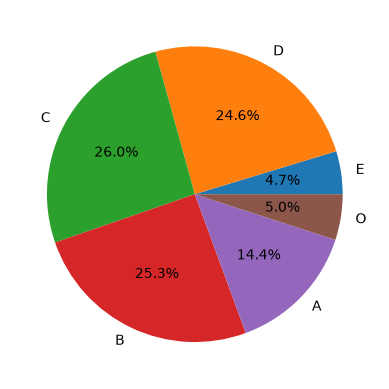

In [176]:
a = df.copy()
a["mean score"] = a[["math score", "reading score", "writing score"]].mean(axis=1)

def b(x):
    if x <= 40:
        return "E"
    elif x <= 60:
        return "D"
    elif x <= 70:
        return "C"
    elif x <= 80:
        return "B"
    elif x <= 90:
        return "A"
    return "O"

a["grade"] = a["mean score"].apply(b)
a.loc[a["math score"] < 40, "grade"] = "E"

c = a["grade"].value_counts().reindex(["E", "D", "C", "B", "A", "O"], fill_value=0)
c.plot.pie(autopct="%1.1f%%")
plt.show()

#### 10. Постройте countplot, показывающий зависимость между итоговой оценкой студентов и его полом. Студенты какого пола получили больше оценок О, А, В

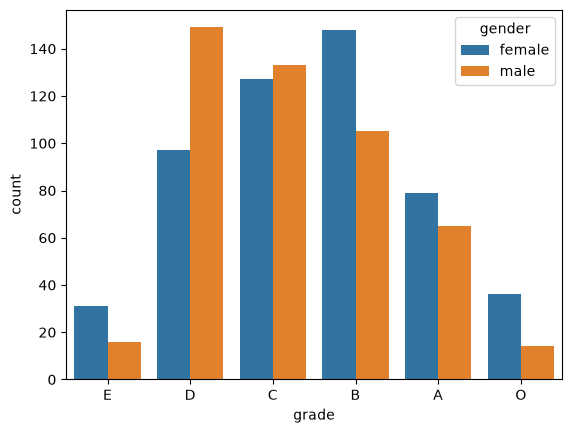

In [186]:
a = df.copy()
a["mean score"] = a[["math score", "reading score", "writing score"]].mean(axis=1)

def b(x):
    if x <= 40:
        return "E"
    elif x <= 60:
        return "D"
    elif x <= 70:
        return "C"
    elif x <= 80:
        return "B"
    elif x <= 90:
        return "A"
    return "O"

a["grade"] = a["mean score"].apply(b)
a.loc[a["math score"] < 40, "grade"] = "E"

plt.figure()
sns.countplot(data=a, x="grade", hue="gender", order=["E", "D", "C", "B", "A", "O"])
plt.show()

# больше оценок О, А, В, получили студенты женского пола